# Acquisition-Cue Audit on BHSig260 (local-first, resumable)

Extends the acquisition-cue audit of v4a from CEDAR to the Bengali and Devanagari partitions
of BHSig260 under an identical procedure.

**Changes in this version**
- Runs locally first -> Colab/Drive is only a fallback.
- Statistics are checkpointed to `v8_stats_cache.csv` every 500 images. If the run stops for any
  reason, re-running the notebook resumes where it left off instead of starting over.
- CEDAR folder is matched loosely, so `cedar (1)` is found.

# Acquisition-Cue Audit on BHSig260

This notebook extends the acquisition-cue audit of v4a from CEDAR to the Bengali and
Devanagari partitions of BHSig260, under an identical procedure.

**Purpose.** v4a established that CEDAR's genuine and forged scans are separable at
AUC 1.0000 on the mean grey level of the unprocessed image, and v4b established that this
property belongs to the corpus rather than to the preprocessing applied to it. Neither
result establishes whether the effect is specific to CEDAR or general to offline signature
corpora. BHSig260 is reported to be distributed in binarised form; if that is so, an
intensity-based cue is structurally impossible in it, and the same audit applied to it
provides the control condition that distinguishes a property of one corpus from a property
of the measurement procedure.

**Procedure.** Three corpora are read without modification. Nine statistics that carry no
information about signature shape are computed from each unprocessed image. For each writer,
the area under the ROC curve is computed for each statistic as a score separating that
writer's genuine from that writer's forged signatures. Results are reported per corpus.

**Scope.** No model is fitted and no signature feature is extracted in this notebook. The
audit operates on the raw files as distributed.

In [1]:
%pip install matplotlib 
%pip install scikit-learn

Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.


In [ ]:
# ---- Configuration -------------------------------------------------------
import os, re, sys, json, math, warnings
import numpy as np
import pandas as pd
warnings.filterwarnings("ignore")

LOCAL_BASE = r"C:\Users\__\Downloads\bhsig\bhsig260-dataset"   # preferred
COLAB_BASE = "/content/drive/MyDrive/bhsig260-dataset"            # fallback only

CORPORA = {
    "CEDAR":   "cedar",             # also matches "cedar (1)", "cedar-dataset", ...
    "Hindi":   "bhsig260-hindi",
    "Bengali": "bhsig260-bengali",
}

SPLIT_SEED   = 20261014
DEV_FRACTION = 0.45
OTSU_FOR_FILL = True
RANDOM_STATE = 0
CHECKPOINT_EVERY = 500
CACHE_FILE = "v8_stats_cache.csv"

def resolve_base():
    # 1) local folder
    for cand in (LOCAL_BASE, os.path.join(os.getcwd(), "bhsig260-dataset")):
        if os.path.isdir(cand):
            return cand, "local"
    # 2) Colab / Google Drive fallback
    if os.path.isdir(COLAB_BASE):
        return COLAB_BASE, "colab (already mounted)"
    try:
        from google.colab import drive
        drive.mount("/content/drive")
        if os.path.isdir(COLAB_BASE):
            return COLAB_BASE, "colab"
    except ImportError:
        pass
    raise FileNotFoundError(
        f"Dataset folder not found.\n  tried: {LOCAL_BASE}\n  tried: {COLAB_BASE}\n"
        "Fix LOCAL_BASE above.")

BASE, WHERE = resolve_base()
print("numpy", np.__version__, "| pandas", pd.__version__)
print("Running on:", WHERE)
print("BASE:", BASE)
print("Entries under BASE:", sorted(os.listdir(BASE))[:20])

try:
    display
except NameError:
    from IPython.display import display

## 1. Locating the corpora

Each corpus root is searched for recursively. Roots are matched exactly, then case-insensitively,
then by prefix (so `cedar (1)` matches `cedar`). A corpus that cannot be found is reported and excluded.

In [24]:
IMG_EXT = {".png", ".jpg", ".jpeg", ".tif", ".tiff", ".bmp"}

def find_root(base, name):
    name = name.lower()
    def scan(folder):
        try:
            entries = [d for d in os.listdir(folder) if os.path.isdir(os.path.join(folder, d))]
        except OSError:
            return None
        for d in entries:                       # exact (case-insensitive)
            if d.lower() == name:
                return os.path.join(folder, d)
        for d in entries:                       # prefix, e.g. "cedar (1)"
            if d.lower().startswith(name):
                return os.path.join(folder, d)
        return None
    hit = scan(base)
    if hit: return hit
    for d in sorted(os.listdir(base)):          # one level deeper
        p = os.path.join(base, d)
        if os.path.isdir(p):
            hit = scan(p)
            if hit: return hit
    return None

def walk_images(root):
    out = []
    for dirpath, _, files in os.walk(root):
        for f in files:
            if os.path.splitext(f)[1].lower() in IMG_EXT:
                out.append(os.path.join(dirpath, f))
    return out

ROOTS, IMAGES = {}, {}
for key, folder in CORPORA.items():
    r = find_root(BASE, folder)
    ROOTS[key] = r
    IMAGES[key] = walk_images(r) if r else []
    print(f"{key:8s} root={r}  images={len(IMAGES[key])}")

CEDAR    root=C:\Users\ogrla\Downloads\bhsig\bhsig260-dataset\cedar  images=2640
Hindi    root=C:\Users\ogrla\Downloads\bhsig\bhsig260-dataset\bhsig260-hindi  images=8640
Bengali  root=C:\Users\ogrla\Downloads\bhsig\bhsig260-dataset\bhsig260-bengali  images=5400


## 2. Parsing filenames into a manifest

- **CEDAR**: `original_<writer>_<index>.png` genuine, `forgeries_<writer>_<index>.png` forged.
- **BHSig260**: `<B|H>-S-<writer>-<G|F>-<index>.tif`.

Unparsable files are counted and excluded. A writer needs at least one genuine and one forged signature.

In [25]:
RE_CEDAR = re.compile(r"^(original|forgeries)[_-](\d+)[_-](\d+)", re.I)
RE_BHSIG = re.compile(r"^([BH])-S-(\d+)-([GF])-(\d+)", re.I)

def parse(path, corpus):
    stem = os.path.splitext(os.path.basename(path))[0]
    m = RE_CEDAR.match(stem)
    if m:
        kind, writer, idx = m.group(1).lower(), m.group(2), m.group(3)
        return dict(writer=f"{corpus}-{int(writer):03d}",
                    label="genuine" if kind == "original" else "forged", index=int(idx))
    m = RE_BHSIG.match(stem)
    if m:
        script, writer, gf, idx = m.group(1).upper(), m.group(2), m.group(3).upper(), m.group(4)
        return dict(writer=f"{corpus}-{int(writer):03d}",
                    label="genuine" if gf == "G" else "forged", index=int(idx))
    return None

rows, unparsed = [], {}
for key, root in ROOTS.items():
    if not root:
        unparsed[key] = "root not found"; continue
    bad = 0
    for p in IMAGES[key]:
        rec = parse(p, key)
        if rec is None:
            bad += 1; continue
        rec.update(corpus=key, path=p,
                   rel=os.path.relpath(p, BASE).replace("\\", "/"))
        rows.append(rec)
    unparsed[key] = bad

manifest = pd.DataFrame(rows)
print("unparsed / missing per corpus:", unparsed)
if manifest.empty:
    raise SystemExit("No parsable images found. Check LOCAL_BASE and CORPORA.")

summary = (manifest.groupby(["corpus", "label"]).size().unstack(fill_value=0)
           .assign(writers=manifest.groupby("corpus")["writer"].nunique()))
display(summary)

unparsed / missing per corpus: {'CEDAR': 0, 'Hindi': 0, 'Bengali': 0}


label,forged,genuine,writers
corpus,,,
Bengali,3000,2400,100
CEDAR,1320,1320,55
Hindi,4800,3840,160


In [26]:
# Integrity: every writer must contribute both classes.
per_writer = manifest.groupby(["corpus", "writer", "label"]).size().unstack(fill_value=0)
incomplete = per_writer[(per_writer.get("genuine", 0) == 0) | (per_writer.get("forged", 0) == 0)]
print("writers missing a class:", len(incomplete))
if len(incomplete):
    display(incomplete.head(20))
    manifest = manifest[~manifest.writer.isin(incomplete.index.get_level_values("writer"))]
    print("excluded; remaining images:", len(manifest))

assert manifest.groupby("corpus")["writer"].nunique().min() >= 2, "a corpus has fewer than two usable writers"

writers missing a class: 1


,label,forged,genuine
corpus,writer,,
Hindi,Hindi-123,30,0


excluded; remaining images: 16650


## 3. Development and reserved writers

Same split discipline as v4a. All results use development writers only; reserved writers are not read.

In [27]:
rng = np.random.RandomState(SPLIT_SEED)
dev_writers = []
for corpus, grp in manifest.groupby("corpus"):
    ws = np.array(sorted(grp.writer.unique()))
    perm = rng.permutation(len(ws))
    k = max(2, int(round(DEV_FRACTION * len(ws))))
    dev_writers.extend(ws[perm[:k]].tolist())
dev_writers = set(dev_writers)

manifest["split"] = np.where(manifest.writer.isin(dev_writers), "dev", "reserved")
print(manifest.groupby(["corpus", "split"])["writer"].nunique().unstack(fill_value=0))

dev = manifest[manifest.split == "dev"].reset_index(drop=True)
print("development images:", len(dev))

split    dev  reserved
corpus                
Bengali   45        55
CEDAR     25        30
Hindi     72        87
development images: 7518


## 4. Characterising the corpora

Number of distinct intensity levels per corpus. Two levels means binarised, so no intensity cue is possible.

In [28]:
from PIL import Image

def load_gray(path):
    with Image.open(path) as im:
        if im.mode not in ("L", "I;16", "I"):
            im = im.convert("L")
        a = np.asarray(im)
    if a.dtype != np.uint8:
        a = (255.0 * (a.astype(np.float64) - a.min()) / max(1e-9, (a.max() - a.min()))).astype(np.uint8)
    return a

level_rows = []
for corpus, grp in dev.groupby("corpus"):
    sample = grp.sample(n=min(40, len(grp)), random_state=RANDOM_STATE)
    levels = [len(np.unique(load_gray(p))) for p in sample.path]
    level_rows.append(dict(corpus=corpus, n_sampled=len(sample),
                           median_levels=int(np.median(levels)),
                           min_levels=int(np.min(levels)), max_levels=int(np.max(levels))))
levels_df = pd.DataFrame(level_rows)
display(levels_df)

,corpus,n_sampled,median_levels,min_levels,max_levels
0,Bengali,40,2,2,2
1,CEDAR,40,163,137,188
2,Hindi,40,2,2,2


## 5. Non-signature statistics (checkpointed)

Nine statistics plus file size are computed per image. Results are appended to
`v8_stats_cache.csv` every 500 images; on re-run, images already in the cache are skipped,
so an interruption never costs more than the last 500 images.

In [8]:
def otsu_threshold(a):
    hist = np.bincount(a.ravel(), minlength=256).astype(np.float64)
    total = hist.sum()
    if total == 0: return 127
    omega = np.cumsum(hist) / total
    mu = np.cumsum(hist * np.arange(256)) / total
    mu_t = mu[-1]
    denom = omega * (1 - omega)
    denom[denom == 0] = 1e-12
    sigma_b = (mu_t * omega - mu) ** 2 / denom
    return int(np.argmax(sigma_b))

STAT_NAMES = ["mean_gray","std_gray","median_gray","p05_gray","p95_gray",
              "fill_density","height","width","aspect_ratio"]

def stats_for(path):
    a = load_gray(path)
    h, w = a.shape[:2]
    t = otsu_threshold(a) if OTSU_FOR_FILL else 127
    fill = float((a <= t).mean())
    return [float(a.mean()), float(a.std()), float(np.median(a)),
            float(np.percentile(a, 5)), float(np.percentile(a, 95)),
            fill, float(h), float(w), float(w) / float(h) if h else np.nan]

# ---- resume from cache ----
recs = []
if os.path.exists(CACHE_FILE):
    cached = pd.read_csv(CACHE_FILE)
    cached = cached[cached.rel.isin(set(dev.rel))]      # keep only rows for the current dev set
    recs = cached.to_dict("records")
done = {r["rel"] for r in recs}
todo = [r for r in dev.itertuples(index=False) if r.rel not in done]
print(f"cached: {len(done)} | to compute: {len(todo)} | total dev: {len(dev)}")

def flush():
    pd.DataFrame(recs).to_csv(CACHE_FILE, index=False)

failed = []
try:
    for i, r in enumerate(todo, 1):
        try:
            s = stats_for(r.path)
            recs.append(dict(rel=r.rel, corpus=r.corpus, writer=r.writer, label=r.label,
                             file_size=os.path.getsize(r.path), **dict(zip(STAT_NAMES, s))))
        except Exception as e:
            failed.append((r.path, repr(e)))
        if i % CHECKPOINT_EVERY == 0:
            flush()
            print(f"{len(recs)}/{len(dev)} images done (checkpoint saved)")
finally:
    flush()          # also runs if you interrupt the cell

print("failed files:", len(failed))
for p, e in failed[:10]:
    print("  ", p, e)

S = pd.DataFrame(recs)
print("rows:", len(S))
display(S.groupby(["corpus","label"])[["mean_gray","fill_density","file_size"]].mean().round(3))

cached: 0 | to compute: 7518 | total dev: 7518
500/7518 images done (checkpoint saved)
1000/7518 images done (checkpoint saved)
1500/7518 images done (checkpoint saved)
2000/7518 images done (checkpoint saved)
2500/7518 images done (checkpoint saved)
3000/7518 images done (checkpoint saved)
3500/7518 images done (checkpoint saved)
4000/7518 images done (checkpoint saved)
4500/7518 images done (checkpoint saved)
5000/7518 images done (checkpoint saved)
5500/7518 images done (checkpoint saved)
6000/7518 images done (checkpoint saved)
6500/7518 images done (checkpoint saved)
7000/7518 images done (checkpoint saved)
7500/7518 images done (checkpoint saved)
failed files: 0
rows: 7518


mean_gray  fill_density   file_size
corpus  label                                       
Bengali forged     247.263         0.030  269568.482
        genuine    248.296         0.026  288250.047
CEDAR   forged     248.328         0.036   83173.115
        genuine    235.930         0.034  106618.868
Hindi   forged     245.924         0.036  278142.258
        genuine    247.805         0.028  281992.865

## 6. Per-writer separability

Per writer and statistic, AUC of the statistic as a score for genuine vs forged, reported as
max(AUC, 1 - AUC), then averaged across writers.

In [9]:
from sklearn.metrics import roc_auc_score

ALL_STATS = STAT_NAMES + ["file_size"]

def writer_auc(df, stat):
    y = (df.label == "forged").astype(int).values
    x = df[stat].values.astype(float)
    if len(np.unique(y)) < 2 or np.allclose(np.nanstd(x), 0):
        return np.nan
    try:
        a = roc_auc_score(y, x)
    except Exception:
        return np.nan
    return max(a, 1.0 - a)

rows = []
for (corpus, writer), grp in S.groupby(["corpus", "writer"]):
    rec = dict(corpus=corpus, writer=writer)
    for st in ALL_STATS:
        rec[st] = writer_auc(grp, st)
    rows.append(rec)
AUC = pd.DataFrame(rows)

table = AUC.groupby("corpus")[ALL_STATS].mean().round(4)
table.insert(0, "writers", AUC.groupby("corpus").size())
display(table)

,writers,mean_gray,std_gray,median_gray,p05_gray,p95_gray,fill_density,height,width,aspect_ratio,file_size
corpus,,,,,,,,,,,
Bengali,45,0.9119,0.9147,0.6042,0.7083,0.6042,0.9144,0.9138,0.8097,0.6460,0.8723
CEDAR,25,1.0000,0.7824,1.0000,0.8622,1.0000,0.7954,0.7723,0.7691,0.7805,0.8325
Hindi,72,0.9093,0.9093,NaN,0.7238,NaN,0.9093,0.7635,0.6965,0.6037,0.6917


In [10]:
# Constant / undefined statistics: NaN means "no variation to exploit", not a failure.
const_rows = []
for corpus, grp in S.groupby("corpus"):
    const = [st for st in ALL_STATS if grp[st].nunique(dropna=True) <= 1]
    undef = [st for st in ALL_STATS if AUC.loc[AUC.corpus == corpus, st].isna().all()]
    const_rows.append(dict(corpus=corpus,
                           constant_in_corpus=", ".join(const) or "none",
                           undefined_auc=", ".join(undef) or "none"))
display(pd.DataFrame(const_rows))

,corpus,constant_in_corpus,undefined_auc
0,Bengali,none,none
1,CEDAR,none,none
2,Hindi,"median_gray, p95_gray","median_gray, p95_gray"


In [11]:
perfect = (AUC[ALL_STATS] >= 0.99999).groupby(AUC.corpus).mean().round(4)
perfect.insert(0, "writers", AUC.groupby("corpus").size())
print("Fraction of writers with complete separation")
display(perfect)

Fraction of writers with complete separation


,writers,mean_gray,std_gray,median_gray,p05_gray,p95_gray,fill_density,height,width,aspect_ratio,file_size
corpus,,,,,,,,,,,
Bengali,45,0.4444,0.4444,0.0,0.0222,0.0,0.4444,0.60,0.1778,0.0,0.60
CEDAR,25,1.0000,0.1200,1.0,0.3200,1.0,0.0800,0.04,0.0000,0.0,0.28
Hindi,72,0.3333,0.3333,0.0,0.0139,0.0,0.3333,0.25,0.0000,0.0,0.00


In [12]:
head = AUC.groupby("corpus")["mean_gray"].agg(["count","mean","median","min","max"]).round(4)
head.columns = ["writers","mean_AUC","median_AUC","min_AUC","max_AUC"]
display(head)

if "CEDAR" in head.index:
    for other in [c for c in head.index if c != "CEDAR"]:
        d = head.loc["CEDAR","mean_AUC"] - head.loc[other,"mean_AUC"]
        print(f"CEDAR minus {other}: {d:+.4f} mean per-writer AUC on mean grey level")

,writers,mean_AUC,median_AUC,min_AUC,max_AUC
corpus,,,,,
Bengali,45,0.9119,0.9944,0.5292,1.0
CEDAR,25,1.0000,1.0000,1.0000,1.0
Hindi,72,0.9093,0.9764,0.5069,1.0


CEDAR minus Bengali: +0.0881 mean per-writer AUC on mean grey level
CEDAR minus Hindi: +0.0907 mean per-writer AUC on mean grey level


## 7. Figure

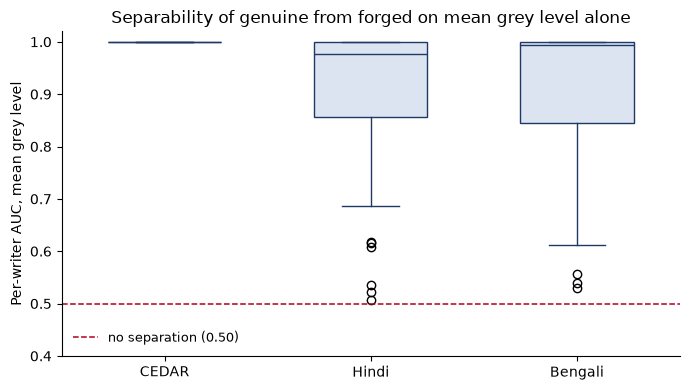

In [13]:
import matplotlib.pyplot as plt

order = [c for c in ["CEDAR","Hindi","Bengali"] if c in AUC.corpus.unique()]
data = [AUC.loc[AUC.corpus == c, "mean_gray"].dropna().values for c in order]

fig, ax = plt.subplots(figsize=(7, 4))
bp = ax.boxplot(data, patch_artist=True, widths=0.55)
for b in bp["boxes"]:
    b.set_facecolor("#DCE4F2"); b.set_edgecolor("#1F3864")
for el in ("whiskers","caps","medians"):
    for ln in bp[el]: ln.set_color("#1F3864")
ax.axhline(0.5, color="#B00020", lw=1.1, ls="--", label="no separation (0.50)")
ax.set_xticklabels(order)
ax.set_ylabel("Per-writer AUC, mean grey level")
ax.set_title("Separability of genuine from forged on mean grey level alone")
ax.set_ylim(0.4, 1.02); ax.legend(frameon=False, fontsize=9)
ax.spines[["top","right"]].set_visible(False)
plt.tight_layout(); plt.show()

In [14]:
AUC.to_csv("v8_per_writer_auc.csv", index=False)
table.to_csv("v8_corpus_summary.csv")
levels_df.to_csv("v8_intensity_levels.csv", index=False)
print("written: v8_per_writer_auc.csv, v8_corpus_summary.csv, v8_intensity_levels.csv")

written: v8_per_writer_auc.csv, v8_corpus_summary.csv, v8_intensity_levels.csv


## 8. Interpretation

If mean grey level separates genuine from forged on CEDAR at or near AUC 1.0000 while falling to
about 0.5 on both BHSig260 partitions, the cue is a property of CEDAR and not of the audit procedure.

If the cue is present in all three corpora, the finding generalises and the requirement for a
non-signature control applies to offline signature benchmarks more broadly.

The intensity-level measurement in Section 4 governs which reading applies: an intensity cue cannot
exist in a two-level corpus, so a non-trivial AUC on `mean_gray` there would mean the corpus is not
binarised as distributed.

## 9. Does the cue survive preprocessing?

Sections 5 to 7 measure the cue on the files as distributed. The verification experiments do
not operate on those files; they operate on the output of the preprocessing pipeline. The
quantity that belongs in the manuscript is therefore the separability that remains **after**
preprocessing, which this section measures by decomposing the pipeline into stages and
recomputing the same statistics at each one.

**Stages.** S0 is the file as distributed. S1 inverts the greyscale so that ink carries high
values. S2 identifies ink by an Otsu threshold and suppresses the background. S3 crops to a
density-filtered bounding box and pads until the aspect ratio is at most 2.5. S4 resizes to
100 by 100, which is the representation every model in this project actually receives.

**Expectation to be tested, not assumed.** Image height, width and file size cannot survive
S4, because every image leaves that stage at identical dimensions; their AUC should become
undefined. Ink coverage is a ratio and should survive. Whether the CEDAR background cue
survives is the open question, and v4b's finding on CEDAR predicts that it does.

**Verification requirement.** The stage functions below are written to match the pipeline as
specified. Before these numbers are reported, the final stage must be checked against the
canonical `preprocess_signature` used from v3 onward; the cell at the end of this section
performs that comparison when the canonical function is available in the session.

In [15]:
# Stage decomposition of the preprocessing pipeline.
from PIL import Image

MAX_ASPECT   = 2.5
TARGET_SIZE  = (100, 100)
DENSITY_KEEP = 0.02      # row/column ink-density floor for the bounding box

def s1_invert(a):
    return (255 - a).astype(np.uint8)

def s2_ink(a):
    t = otsu_threshold(a)
    return np.where(a > t, a, 0).astype(np.uint8)

def s3_crop_pad(a):
    rows = a.sum(axis=1).astype(float); cols = a.sum(axis=0).astype(float)
    rmax = rows.max() if rows.max() > 0 else 1.0
    cmax = cols.max() if cols.max() > 0 else 1.0
    r = np.where(rows >= DENSITY_KEEP * rmax)[0]
    c = np.where(cols >= DENSITY_KEEP * cmax)[0]
    if len(r) == 0 or len(c) == 0:
        b = a
    else:
        b = a[r.min():r.max() + 1, c.min():c.max() + 1]
    h, w = b.shape[:2]
    if h == 0 or w == 0:
        return a
    if w / h > MAX_ASPECT:                      # too wide -> pad height
        new_h = int(np.ceil(w / MAX_ASPECT)); pad = new_h - h
        b = np.pad(b, ((pad // 2, pad - pad // 2), (0, 0)))
    elif h / w > MAX_ASPECT:                    # too tall -> pad width
        new_w = int(np.ceil(h / MAX_ASPECT)); pad = new_w - w
        b = np.pad(b, ((0, 0), (pad // 2, pad - pad // 2)))
    return b.astype(np.uint8)

def s4_resize(a):
    return np.asarray(Image.fromarray(a).resize(TARGET_SIZE, Image.BILINEAR)).astype(np.uint8)

def stages_for(path):
    a0 = load_gray(path)
    a1 = s1_invert(a0)
    a2 = s2_ink(a1)
    a3 = s3_crop_pad(a2)
    a4 = s4_resize(a3)
    return {"S0": a0, "S1": a1, "S2": a2, "S3": a3, "S4": a4}

def stats_from_array(a):
    h, w = a.shape[:2]
    t = otsu_threshold(a) if OTSU_FOR_FILL else 127
    return dict(zip(STAT_NAMES,
        [float(a.mean()), float(a.std()), float(np.median(a)),
         float(np.percentile(a, 5)), float(np.percentile(a, 95)),
         float((a <= t).mean()), float(h), float(w),
         float(w) / float(h) if h else np.nan]))

print("stage functions defined: S0 raw, S1 invert, S2 ink, S3 crop+pad, S4 resize",
      TARGET_SIZE, "| max aspect", MAX_ASPECT)

stage functions defined: S0 raw, S1 invert, S2 ink, S3 crop+pad, S4 resize (100, 100) | max aspect 2.5


In [16]:
# Compute statistics at every stage. Checkpointed exactly like Section 5.
STAGE_CACHE = "v8_staged_cache.csv"
STAGES = ["S0","S1","S2","S3","S4"]

srecs = []
if os.path.exists(STAGE_CACHE):
    sc = pd.read_csv(STAGE_CACHE)
    sc = sc[sc.rel.isin(set(dev.rel))]
    srecs = sc.to_dict("records")
sdone = {(r["rel"], r["stage"]) for r in srecs}
stodo = [r for r in dev.itertuples(index=False) if (r.rel, "S4") not in sdone]
print(f"cached rows: {len(srecs)} | images to process: {len(stodo)}")

def sflush(): pd.DataFrame(srecs).to_csv(STAGE_CACHE, index=False)

sfailed = []
try:
    for i, r in enumerate(stodo, 1):
        try:
            arrs = stages_for(r.path)
            for st in STAGES:
                srecs.append(dict(rel=r.rel, stage=st, corpus=r.corpus, writer=r.writer,
                                  label=r.label, **stats_from_array(arrs[st])))
        except Exception as e:
            sfailed.append((r.path, repr(e)))
        if i % CHECKPOINT_EVERY == 0:
            sflush(); print(f"{i}/{len(stodo)} images staged (checkpoint saved)")
finally:
    sflush()

print("failed:", len(sfailed))
for p, e in sfailed[:5]: print("  ", p, e)
ST = pd.DataFrame(srecs)
print("staged rows:", len(ST), "| stages:", sorted(ST.stage.unique()))

cached rows: 0 | images to process: 7518
500/7518 images staged (checkpoint saved)
1000/7518 images staged (checkpoint saved)
1500/7518 images staged (checkpoint saved)
2000/7518 images staged (checkpoint saved)
2500/7518 images staged (checkpoint saved)
3000/7518 images staged (checkpoint saved)
3500/7518 images staged (checkpoint saved)
4000/7518 images staged (checkpoint saved)
4500/7518 images staged (checkpoint saved)
5000/7518 images staged (checkpoint saved)
5500/7518 images staged (checkpoint saved)
6000/7518 images staged (checkpoint saved)
6500/7518 images staged (checkpoint saved)
7000/7518 images staged (checkpoint saved)
7500/7518 images staged (checkpoint saved)
failed: 0
staged rows: 37590 | stages: ['S0', 'S1', 'S2', 'S3', 'S4']


In [17]:
# Per-writer AUC at each stage, for each statistic.
STAGE_STATS = STAT_NAMES   # file_size is a property of the file, so it exists only at S0

rows = []
for (corpus, stage, writer), grp in ST.groupby(["corpus","stage","writer"]):
    rec = dict(corpus=corpus, stage=stage, writer=writer)
    for st in STAGE_STATS:
        rec[st] = writer_auc(grp, st)
    rows.append(rec)
AUC_ST = pd.DataFrame(rows)

pivot = (AUC_ST.groupby(["corpus","stage"])[STAGE_STATS].mean()
         .round(4).reset_index().set_index(["corpus","stage"]).sort_index())
print("Mean per-writer AUC by preprocessing stage")
display(pivot)

Mean per-writer AUC by preprocessing stage


mean_gray  std_gray  median_gray  p05_gray  p95_gray  \
corpus  stage                                                         
Bengali S0        0.9119    0.9147       0.6042    0.7083    0.6042   
        S1        0.9119    0.9147       0.6042    0.6042    0.7083   
        S2        0.9145    0.9146          NaN       NaN    0.7292   
        S3        0.8883    0.8883          NaN       NaN    0.7220   
        S4        0.8884    0.9126          NaN       NaN    0.9012   
CEDAR   S0        1.0000    0.7824       1.0000    0.8622    1.0000   
        S1        1.0000    0.7824       1.0000    1.0000    0.8622   
        S2        0.7327    0.7581          NaN       NaN    0.6683   
        S3        0.7499    0.7810          NaN       NaN    0.6941   
        S4        0.7497    0.7674          NaN       NaN    0.7638   
Hindi   S0        0.9093    0.9093          NaN    0.7238       NaN   
        S1        0.9093    0.9093          NaN       NaN    0.7238   
        S2        0.9093    0.9093          NaN       NaN    0.7696   
        S3        0.7594    0.7594          NaN       NaN    0.6034   
        S4        0.7596    0.7560          NaN       NaN    0.7523   

               fill_density  height   width  aspect_ratio  
corpus  stage                                              
Bengali S0           0.9144  0.9138  0.8097        0.6460  
        S1           0.9144  0.9138  0.8097        0.6460  
        S2           0.9144  0.9138  0.8097        0.6460  
        S3           0.8883  0.7985  0.7988        0.5930  
        S4           0.8411     NaN     NaN           NaN  
CEDAR   S0           0.7954  0.7723  0.7691        0.7805  
        S1           0.7954  0.7723  0.7691        0.7805  
        S2           0.7954  0.7723  0.7691        0.7805  
        S3           0.7238  0.7555  0.7966        0.6626  
        S4           0.7009     NaN     NaN           NaN  
Hindi   S0           0.9093  0.7635  0.6965        0.6037  
        S1           0.9093  0.7635  0.6965        0.6037  
        S2           0.9093  0.7635  0.6965        0.6037  
        S3           0.7594  0.8291  0.8275        0.5855  
        S4           0.7613     NaN     NaN           NaN

In [18]:
# The two statistics that matter: the corpus-specific cue, and ink coverage.
focus = (AUC_ST.groupby(["corpus","stage"])[["mean_gray","fill_density","height","width"]]
         .mean().round(4).unstack(0))
print("mean_gray / fill_density / height / width, by stage and corpus")
display(focus)

print("\nSurvival of the cue through the pipeline (mean_gray):")
for c in ["CEDAR","Hindi","Bengali"]:
    sub = AUC_ST[AUC_ST.corpus == c].groupby("stage")["mean_gray"].mean()
    if len(sub):
        s0, s4 = sub.get("S0", np.nan), sub.get("S4", np.nan)
        print(f"  {c:8s} S0 {s0:.4f} -> S4 {s4:.4f}   (change {s4-s0:+.4f})")

# Consistency check: stage S0 recomputes Section 5's statistics and must agree with them.
chk = (AUC_ST[AUC_ST.stage == "S0"].groupby("corpus")["mean_gray"].mean()
       .to_frame("staged_S0").join(AUC.groupby("corpus")["mean_gray"].mean().to_frame("section6")))
chk["diff"] = (chk.staged_S0 - chk.section6).abs()
display(chk.round(4))
assert chk["diff"].max() < 1e-6, "staged S0 disagrees with Section 5/6; the two paths are not reading the same images"
print("S0 agrees with Section 6 for every corpus.")

mean_gray / fill_density / height / width, by stage and corpus


mean_gray                 fill_density                  height          \
corpus   Bengali   CEDAR   Hindi      Bengali   CEDAR   Hindi Bengali   CEDAR   
stage                                                                           
S0        0.9119  1.0000  0.9093       0.9144  0.7954  0.9093  0.9138  0.7723   
S1        0.9119  1.0000  0.9093       0.9144  0.7954  0.9093  0.9138  0.7723   
S2        0.9145  0.7327  0.9093       0.9144  0.7954  0.9093  0.9138  0.7723   
S3        0.8883  0.7499  0.7594       0.8883  0.7238  0.7594  0.7985  0.7555   
S4        0.8884  0.7497  0.7596       0.8411  0.7009  0.7613     NaN     NaN   

                 width                  
corpus   Hindi Bengali   CEDAR   Hindi  
stage                                   
S0      0.7635  0.8097  0.7691  0.6965  
S1      0.7635  0.8097  0.7691  0.6965  
S2      0.7635  0.8097  0.7691  0.6965  
S3      0.8291  0.7988  0.7966  0.8275  
S4         NaN     NaN     NaN     NaN


Survival of the cue through the pipeline (mean_gray):
  CEDAR    S0 1.0000 -> S4 0.7497   (change -0.2503)
  Hindi    S0 0.9093 -> S4 0.7596   (change -0.1497)
  Bengali  S0 0.9119 -> S4 0.8884   (change -0.0236)


,staged_S0,section6,diff
corpus,,,
Bengali,0.9119,0.9119,0.0
CEDAR,1.0000,1.0000,0.0
Hindi,0.9093,0.9093,0.0


S0 agrees with Section 6 for every corpus.


In [19]:
# Statistics rendered constant by a stage show as NaN; report that explicitly.
rows = []
for (corpus, stage), grp in ST.groupby(["corpus","stage"]):
    const = [st for st in STAGE_STATS if grp[st].nunique(dropna=True) <= 1]
    rows.append(dict(corpus=corpus, stage=stage, constant=", ".join(const) or "none"))
display(pd.DataFrame(rows).pivot(index="stage", columns="corpus", values="constant"))

corpus,Bengali,CEDAR,Hindi
stage,,,
S0,none,none,"median_gray, p95_gray"
S1,none,none,"median_gray, p05_gray"
S2,"median_gray, p05_gray","median_gray, p05_gray","median_gray, p05_gray"
S3,"median_gray, p05_gray","median_gray, p05_gray","median_gray, p05_gray"
S4,"median_gray, p05_gray, height, width, aspect_r...","median_gray, p05_gray, height, width, aspect_r...","median_gray, p05_gray, height, width, aspect_r..."


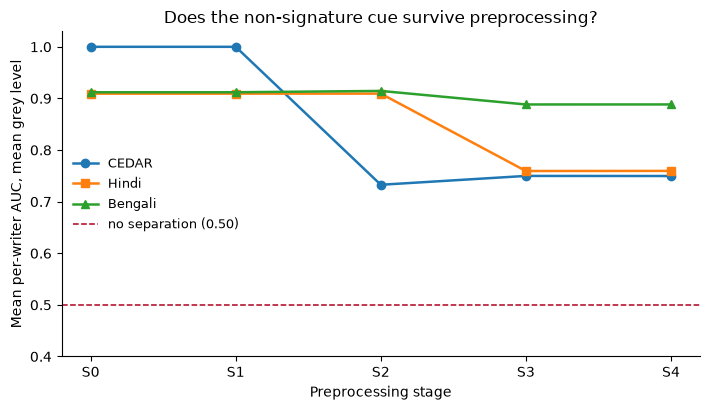

In [20]:
# Figure: how the cue decays, or fails to, across stages.
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(7.2, 4.2))
marks = {"CEDAR":"o", "Hindi":"s", "Bengali":"^"}
for c in [x for x in ["CEDAR","Hindi","Bengali"] if x in AUC_ST.corpus.unique()]:
    sub = AUC_ST[AUC_ST.corpus == c].groupby("stage")["mean_gray"].mean().reindex(STAGES)
    ax.plot(STAGES, sub.values, marker=marks.get(c,"o"), lw=1.8, label=c)
ax.axhline(0.5, color="#B00020", lw=1.1, ls="--", label="no separation (0.50)")
ax.set_ylabel("Mean per-writer AUC, mean grey level")
ax.set_xlabel("Preprocessing stage")
ax.set_title("Does the non-signature cue survive preprocessing?")
ax.set_ylim(0.4, 1.03); ax.legend(frameon=False, fontsize=9)
ax.spines[["top","right"]].set_visible(False)
plt.tight_layout(); plt.show()

In [21]:
# Verification against the canonical pipeline, when it is available in the session.
# Replace the import below with the project's own preprocess_signature to run the check.
try:
    preprocess_signature            # defined by an earlier notebook or an imported module
except NameError:
    print("canonical preprocess_signature not in session - stage check SKIPPED.")
    print("Run this cell after defining it to confirm S4 reproduces the canonical output.")
else:
    import random
    sample = dev.sample(n=min(50, len(dev)), random_state=RANDOM_STATE)
    mismatches = 0
    for r in sample.itertuples(index=False):
        mine = stages_for(r.path)["S4"]
        theirs = np.asarray(preprocess_signature(r.path))
        if mine.shape != theirs.shape or not np.array_equal(mine, theirs):
            mismatches += 1
    print(f"stage-4 vs canonical: {len(sample)-mismatches}/{len(sample)} identical")
    assert mismatches == 0, "S4 does not reproduce the canonical pipeline; reconcile before reporting"

canonical preprocess_signature not in session - stage check SKIPPED.
Run this cell after defining it to confirm S4 reproduces the canonical output.


In [22]:
AUC_ST.to_csv("v8_staged_per_writer_auc.csv", index=False)
pivot.to_csv("v8_staged_summary.csv")
print("written: v8_staged_per_writer_auc.csv, v8_staged_summary.csv")

written: v8_staged_per_writer_auc.csv, v8_staged_summary.csv


## 10. Reading the staged result

Three outcomes are distinguishable.

If `mean_gray` separability on CEDAR holds near 1.0000 through S4, the background cue survives
the preprocessing this project applies, and every accuracy figure computed on CEDAR must be
reported beside the trivial control rather than on its own.

If separability falls to approximately 0.5 by S4 in every corpus, the cue is confined to the
files as distributed and does not reach the models, in which case the audit remains a finding
about the corpora but does not qualify this study's own measurements.

If height, width and file size become undefined at S4 while ink coverage persists, the
geometric component of the BHSig260 leak is removed by preprocessing and the residual is
ink coverage, which is a partly signature-bearing quantity and must be described as such
rather than as a pure artifact.